In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import warnings
warnings.filterwarnings('ignore')

In [55]:
#loading the dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [56]:
#inspecting the dataset
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("Dataframe missing values:")
print(df.isnull().sum())

print("Dataframe duplicates:")
print(df.duplicated().sum())

df.describe()

Dataset shape: (7043, 21)

Column names:
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   s

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [57]:
# Count empty or whitespace-only values
(df['TotalCharges'].str.strip() == '').sum()

np.int64(11)

In [58]:
#convert TotalCharges to numeric
# Remove leading and trailing spaces
df['TotalCharges'] = df['TotalCharges'].str.strip()

# Convert to numeric
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

print(df['TotalCharges'].isnull().sum())

11


In [59]:
#rows with null values in TotalCharges
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [60]:
df.loc[
    df['TotalCharges'].isnull(),
    ['tenure', 'MonthlyCharges', 'TotalCharges']
]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [61]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [62]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

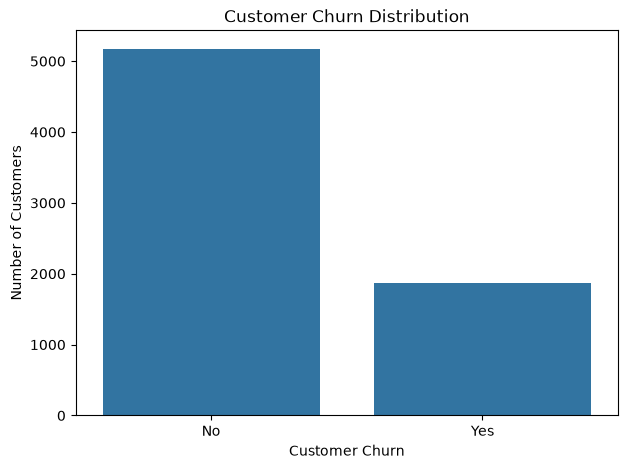

In [63]:
#target variable distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.xlabel('Customer Churn')
plt.ylabel('Number of Customers')
plt.show()

In [64]:
# Replace missing TotalCharges with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges'].isnull().sum()

np.int64(0)

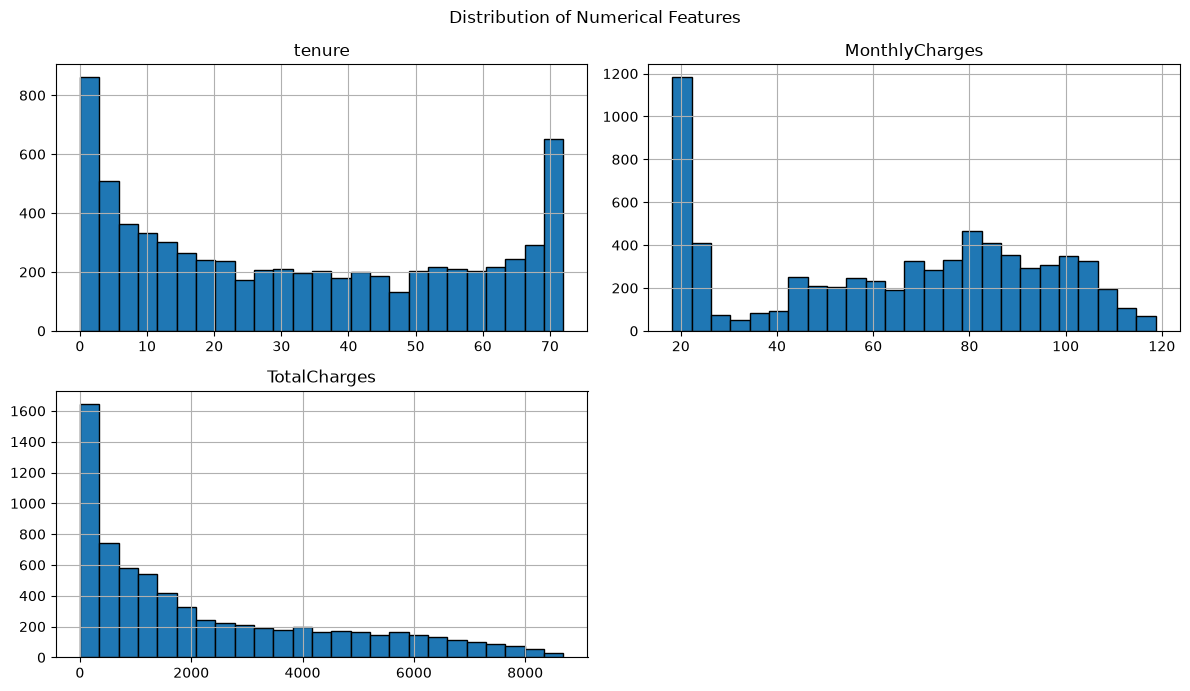

In [65]:
#feature distribution for numerical features
numerical_features = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

df[numerical_features].hist(
    figsize=(12, 7),
    bins=25,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

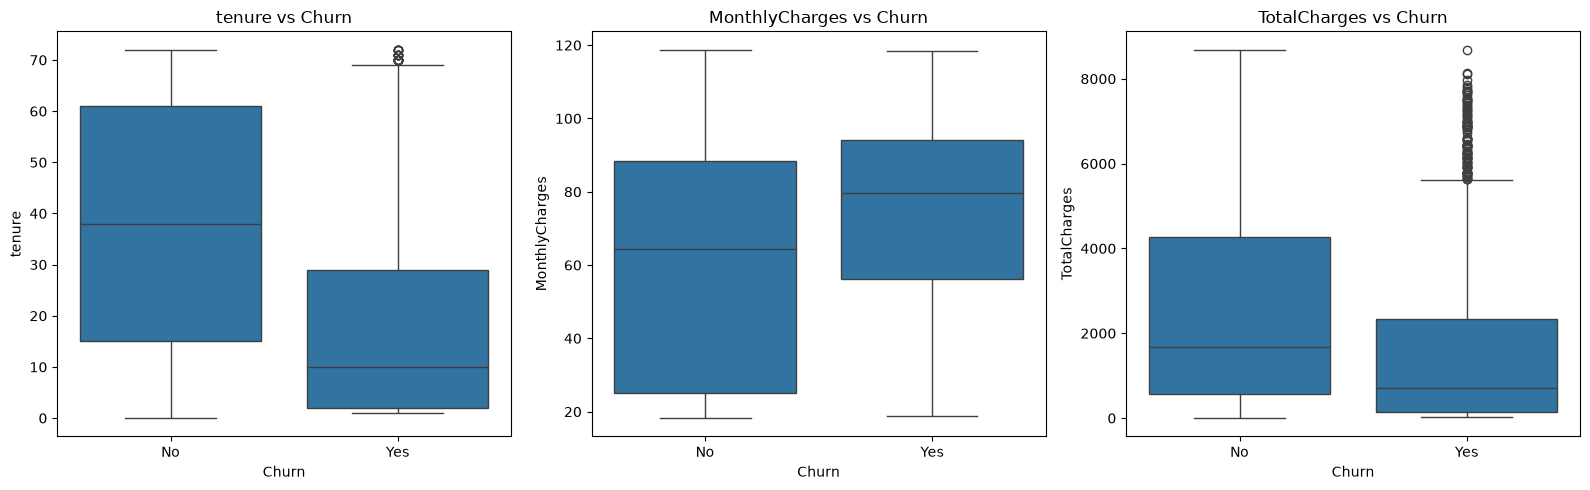

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feature in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        x='Churn',
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f'{feature} vs Churn')

plt.tight_layout()
plt.show()

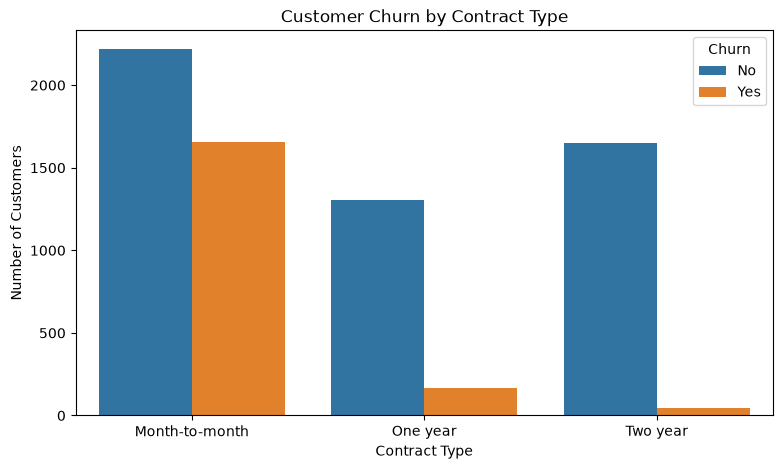

In [67]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn'
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

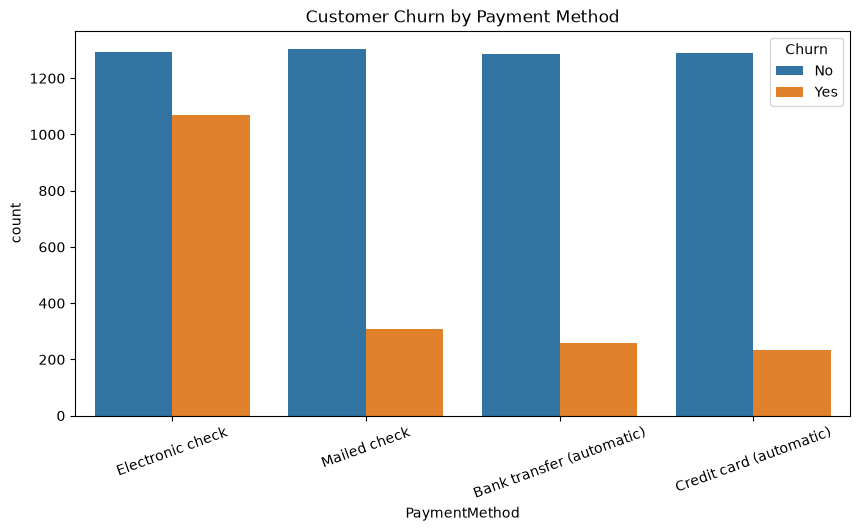

In [68]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn'
)

plt.title('Customer Churn by Payment Method')
plt.xticks(rotation=20)

plt.show()

In [69]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


In [70]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

print(payment_churn)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


In [71]:
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

print(internet_churn)

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


In [72]:
df = df.drop(columns=['customerID'])

In [73]:
#separating features and target variable
X = df.drop(columns=['Churn'])
y = df['Churn']

In [74]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [75]:
#converting target variable to binary
y = y.map({
    'No': 0,
    'Yes': 1
})

In [76]:
#separating numerical and categorical features
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'str', 'category']
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [77]:
#splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=1089,
    stratify=y
)

In [78]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Churn
0    73.46856
1    26.53144
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.450071
1    26.549929
Name: proportion, dtype: float64


In [79]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder

In [80]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [81]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [82]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [83]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [84]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (4930, 19)
Processed training shape: (4930, 45)

Original testing shape: (2113, 19)
Processed testing shape: (2113, 45)


In [85]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=1089,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

In [86]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Churn
0    3622
1    1308
Name: count, dtype: int64

After SMOTE:
Churn
0    3622
1    3622
Name: count, dtype: int64


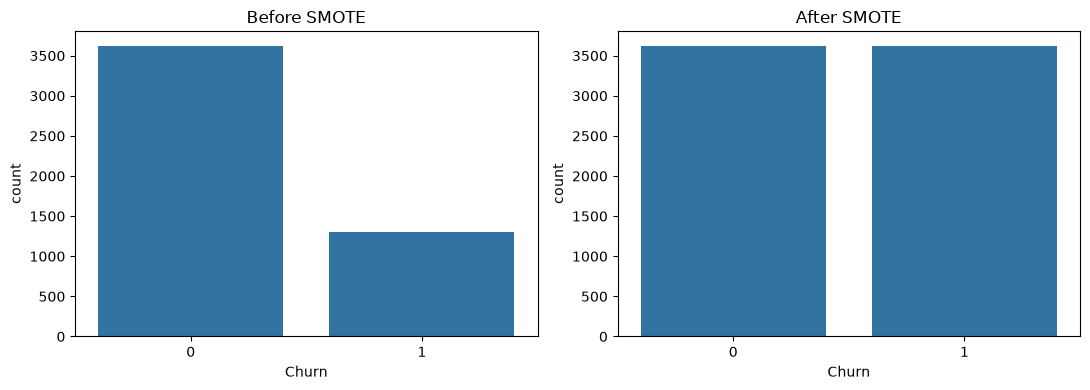

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title('Before SMOTE')
axes[0].set_xlabel('Churn')

sns.countplot(x=y_train_smote, ax=axes[1])
axes[1].set_title('After SMOTE')
axes[1].set_xlabel('Churn')

plt.tight_layout()
plt.show()

In [88]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=1089,
    n_jobs=-1
)

In [89]:
rf_model.fit(
    X_train_smote,
    y_train_smote
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1089
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tot

In [90]:
y_pred_rf = rf_model.predict(X_test_processed)
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

In [91]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Random Forest Performance")
print("-------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Performance
-------------------------
Accuracy: 0.7898722195929957
Precision: 0.610586011342155
Recall: 0.5757575757575758
F1 Score: 0.5926605504587156
ROC-AUC: 0.8324512560413108

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.87      0.86      1552
           1       0.61      0.58      0.59       561

    accuracy                           0.79      2113
   macro avg       0.73      0.72      0.73      2113
weighted avg       0.79      0.79      0.79      2113



In [92]:
scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

print("Scale Pos Weight:", scale_pos_weight)

Scale Pos Weight: 2.7691131498470947


In [93]:
# Separate numerical and categorical features
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = X.select_dtypes(include=['object', 'str', 'category']).columns.tolist()

print("Numerical features:", numerical_features)
print("\nNumber of numerical features:", len(numerical_features))

print("\nCategorical features:", categorical_features)
print("\nNumber of categorical features:", len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Number of numerical features: 4

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of categorical features: 15


In [94]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

# Combine both transformations
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [95]:
from imblearn.over_sampling import SMOTENC

# Identify categorical feature positions
categorical_indices = list(range(
    len(numerical_features),
    len(numerical_features) + len(categorical_features)
))

# Configure SMOTENC
smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=1089,
    k_neighbors=5
)

print("Categorical indices:", categorical_indices)
print("SMOTENC configured successfully.")

Categorical indices: [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
SMOTENC configured successfully.


In [96]:
# One-Hot Encode categorical features after SMOTENC
onehot_encoder = ColumnTransformer(transformers=[
    ('num', 'passthrough', list(range(len(numerical_features)))),
    ('cat', OneHotEncoder(handle_unknown='ignore'),
     categorical_indices)
])

In [97]:
from imblearn.pipeline import Pipeline as ImbPipeline

# Create the complete preprocessing and balancing pipeline
preprocessing_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smotenc', smotenc),
    ('onehot', onehot_encoder)
])

print("Complete preprocessing pipeline created successfully.")

Complete preprocessing pipeline created successfully.


In [98]:
from sklearn.ensemble import RandomForestClassifier

rf_model = ImbPipeline(steps=[
    ('preprocessing', preprocessing_pipeline),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=1089,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [100]:
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline

rf_model = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smotenc', smotenc),
    ('onehot', onehot_encoder),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=1089,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [101]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully.")

Random Forest training completed successfully.


In [102]:
# Predict customer churn
y_pred_rf = rf_model.predict(X_test)

# Predict churn probabilities
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully.")
print("Number of predictions:", len(y_pred_rf))

Predictions completed successfully.
Number of predictions: 2113


In [103]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate evaluation metrics
print("Random Forest Performance")
print("-------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Performance
-------------------------
Accuracy: 0.7875059157595835
Precision: 0.5962199312714777
Recall: 0.6185383244206774
F1 Score: 0.6071741032370953
ROC-AUC: 0.8343940083062279

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.85      0.85      1552
           1       0.60      0.62      0.61       561

    accuracy                           0.79      2113
   macro avg       0.73      0.73      0.73      2113
weighted avg       0.79      0.79      0.79      2113



In [104]:
from xgboost import XGBClassifier

print("XGBoost imported successfully.")

XGBoost imported successfully.


In [105]:
xgb_model = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smotenc', smotenc),
    ('onehot', onehot_encoder),
    ('classifier', XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=5,
        random_state=1089,
        eval_metric='logloss',
        n_jobs=-1
    ))
])

print("XGBoost pipeline created successfully.")

XGBoost pipeline created successfully.


In [106]:
# Train XGBoost
xgb_model.fit(X_train, y_train)

print("XGBoost training completed successfully.")

XGBoost training completed successfully.


In [107]:
# Predict customer churn
y_pred_xgb = xgb_model.predict(X_test)

# Predict churn probabilities
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost predictions completed successfully.")
print("Number of predictions:", len(y_pred_xgb))

XGBoost predictions completed successfully.
Number of predictions: 2113


In [108]:
print("XGBoost Performance")
print("-------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Performance
-------------------
Accuracy: 0.7946048272598202
Precision: 0.5954887218045113
Recall: 0.7058823529411765
F1 Score: 0.6460032626427407
ROC-AUC: 0.8502334978039952

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.83      0.86      1552
           1       0.60      0.71      0.65       561

    accuracy                           0.79      2113
   macro avg       0.74      0.77      0.75      2113
weighted avg       0.81      0.79      0.80      2113



In [109]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1089
)

# Random Forest cross-validation
rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=1
)

# XGBoost cross-validation
xgb_cv_scores = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=1
)

print("Random Forest CV ROC-AUC:", rf_cv_scores)
print("Random Forest Mean:", rf_cv_scores.mean())

print("\nXGBoost CV ROC-AUC:", xgb_cv_scores)
print("XGBoost Mean:", xgb_cv_scores.mean())

Random Forest CV ROC-AUC: [0.81342053 0.8154023  0.81625353 0.80163479 0.8231148 ]
Random Forest Mean: 0.8139651901757343

XGBoost CV ROC-AUC: [0.82018496 0.81689523 0.82661265 0.80815339 0.81676753]
XGBoost Mean: 0.8177227532901739


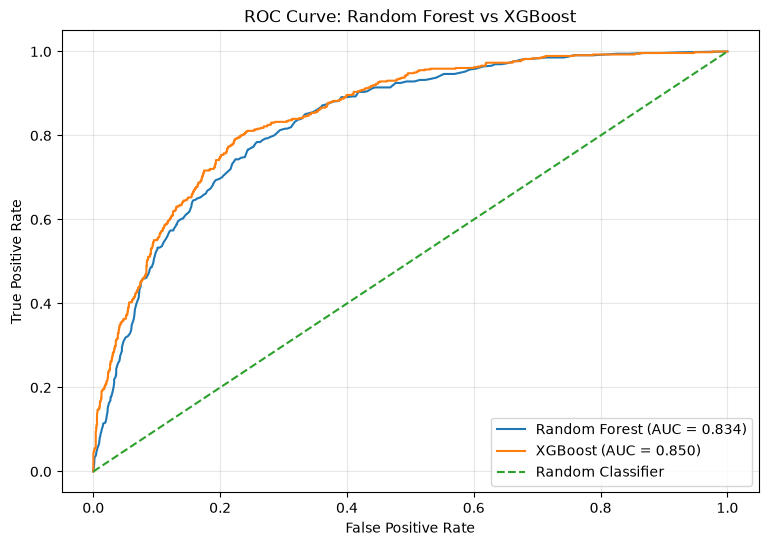

In [110]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curve values
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

# Plot ROC curves
plt.figure(figsize=(9, 6))

plt.plot(
    fpr_rf, tpr_rf,
    label=f'Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})'
)

plt.plot(
    fpr_xgb, tpr_xgb,
    label=f'XGBoost (AUC = {roc_auc_score(y_test, y_prob_xgb):.3f})'
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Random Forest vs XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [111]:
# Extract feature names after One-Hot Encoding
feature_names = xgb_model.named_steps['onehot'].get_feature_names_out(
    xgb_model.named_steps['preprocessor'].get_feature_names_out()
)

# Extract feature importance scores
rf_importance = rf_model.named_steps['classifier'].feature_importances_
xgb_importance = xgb_model.named_steps['classifier'].feature_importances_

# Create comparison DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Random Forest': rf_importance,
    'XGBoost': xgb_importance
})

# Top 10 Random Forest features
rf_top10 = importance_df.sort_values(
    by='Random Forest', ascending=False
).head(10)

# Top 10 XGBoost features
xgb_top10 = importance_df.sort_values(
    by='XGBoost', ascending=False
).head(10)

print("TOP 10 RANDOM FOREST FEATURES")
display(rf_top10)

print("\nTOP 10 XGBOOST FEATURES")
display(xgb_top10)

TOP 10 RANDOM FOREST FEATURES


,Feature,Random Forest,XGBoost
3,num__num__TotalCharges,0.131967,0.008112
1,num__num__tenure,0.128958,0.011794
2,num__num__MonthlyCharges,0.113139,0.006339
36,cat__cat__Contract_0.0,0.071037,0.556300
18,cat__cat__OnlineSecurity_0.0,0.048548,0.054519
43,cat__cat__PaymentMethod_2.0,0.040006,0.031435
27,cat__cat__TechSupport_0.0,0.035671,0.028123
38,cat__cat__Contract_2.0,0.030762,0.011877
16,cat__cat__InternetService_1.0,0.028779,0.080166
20,cat__cat__OnlineSecurity_2.0,0.018302,0.005170



TOP 10 XGBOOST FEATURES


,Feature,Random Forest,XGBoost
36,cat__cat__Contract_0.0,0.071037,0.556300
16,cat__cat__InternetService_1.0,0.028779,0.080166
18,cat__cat__OnlineSecurity_0.0,0.048548,0.054519
35,cat__cat__StreamingMovies_2.0,0.011145,0.033358
43,cat__cat__PaymentMethod_2.0,0.040006,0.031435
27,cat__cat__TechSupport_0.0,0.035671,0.028123
15,cat__cat__InternetService_0.0,0.009818,0.013537
39,cat__cat__PaperlessBilling_0.0,0.014281,0.012446
14,cat__cat__MultipleLines_2.0,0.010936,0.012445
38,cat__cat__Contract_2.0,0.030762,0.011877


In [112]:
# Retrieve the fitted OrdinalEncoder
ordinal_encoder = (
    xgb_model.named_steps['preprocessor']
    .named_transformers_['cat']
    .named_steps['ordinal']
)

# Display category mappings
for feature, categories in zip(categorical_features, ordinal_encoder.categories_):
    print(f"\n{feature}:")
    for code, category in enumerate(categories):
        print(f"  {code} = {category}")


gender:
  0 = Female
  1 = Male

Partner:
  0 = No
  1 = Yes

Dependents:
  0 = No
  1 = Yes

PhoneService:
  0 = No
  1 = Yes

MultipleLines:
  0 = No
  1 = No phone service
  2 = Yes

InternetService:
  0 = DSL
  1 = Fiber optic
  2 = No

OnlineSecurity:
  0 = No
  1 = No internet service
  2 = Yes

OnlineBackup:
  0 = No
  1 = No internet service
  2 = Yes

DeviceProtection:
  0 = No
  1 = No internet service
  2 = Yes

TechSupport:
  0 = No
  1 = No internet service
  2 = Yes

StreamingTV:
  0 = No
  1 = No internet service
  2 = Yes

StreamingMovies:
  0 = No
  1 = No internet service
  2 = Yes

Contract:
  0 = Month-to-month
  1 = One year
  2 = Two year

PaperlessBilling:
  0 = No
  1 = Yes

PaymentMethod:
  0 = Bank transfer (automatic)
  1 = Credit card (automatic)
  2 = Electronic check
  3 = Mailed check


In [113]:
# Function to map encoded features back to original features
def get_original_feature(encoded_feature):

    # Numerical features
    if encoded_feature.startswith('num__num__'):
        return encoded_feature.replace('num__num__', '')

    # Categorical features
    for feature in categorical_features:
        prefix = f'cat__cat__{feature}_'

        if encoded_feature.startswith(prefix):
            return feature

    return encoded_feature


# Create a copy of the importance DataFrame
aggregated_importance = importance_df.copy()

# Map encoded features to original feature names
aggregated_importance['Original Feature'] = (
    aggregated_importance['Feature'].apply(get_original_feature)
)

# Aggregate importance scores
aggregated_importance = (
    aggregated_importance
    .groupby('Original Feature')[['Random Forest', 'XGBoost']]
    .sum()
    .reset_index()
)

# Sort and display Random Forest importance
rf_aggregated = aggregated_importance.sort_values(
    by='Random Forest', ascending=False
)

# Sort and display XGBoost importance
xgb_aggregated = aggregated_importance.sort_values(
    by='XGBoost', ascending=False
)

print("AGGREGATED FEATURE IMPORTANCE - RANDOM FOREST")
display(rf_aggregated.head(10))

print("\nAGGREGATED FEATURE IMPORTANCE - XGBOOST")
display(xgb_aggregated.head(10))

AGGREGATED FEATURE IMPORTANCE - RANDOM FOREST


,Original Feature,Random Forest,XGBoost
16,TotalCharges,0.131967,0.008112
18,tenure,0.128958,0.011794
0,Contract,0.116865,0.578192
4,MonthlyCharges,0.113139,0.006339
10,PaymentMethod,0.075040,0.052222
7,OnlineSecurity,0.070164,0.059690
15,TechSupport,0.053877,0.033619
3,InternetService,0.041383,0.093703
17,gender,0.031908,0.007487
6,OnlineBackup,0.031726,0.016080



AGGREGATED FEATURE IMPORTANCE - XGBOOST


,Original Feature,Random Forest,XGBoost
0,Contract,0.116865,0.578192
3,InternetService,0.041383,0.093703
7,OnlineSecurity,0.070164,0.059690
10,PaymentMethod,0.075040,0.052222
13,StreamingMovies,0.025797,0.043654
15,TechSupport,0.053877,0.033619
5,MultipleLines,0.025940,0.022051
6,OnlineBackup,0.031726,0.016080
14,StreamingTV,0.023960,0.013520
2,DeviceProtection,0.027826,0.013088


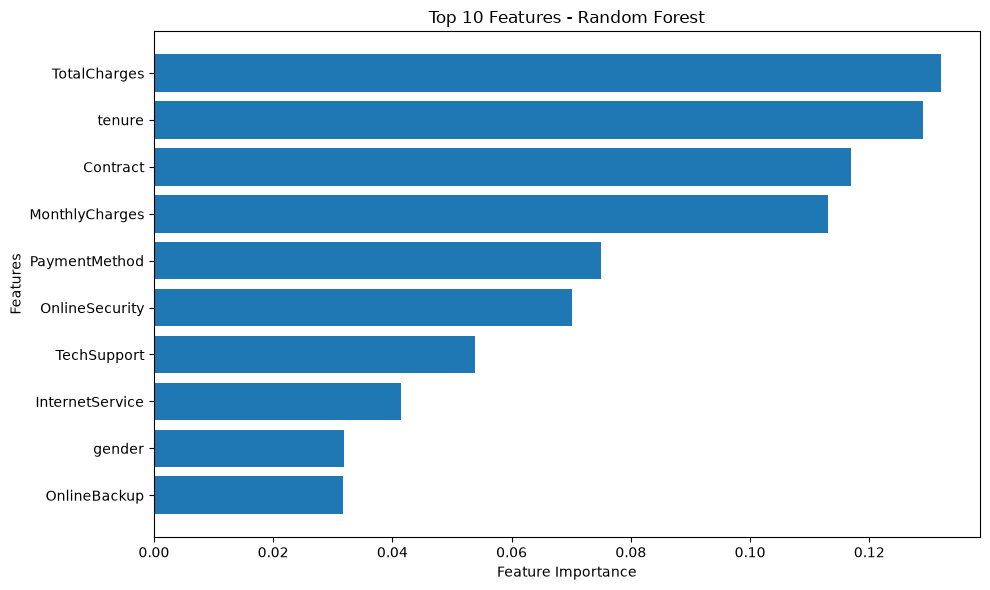

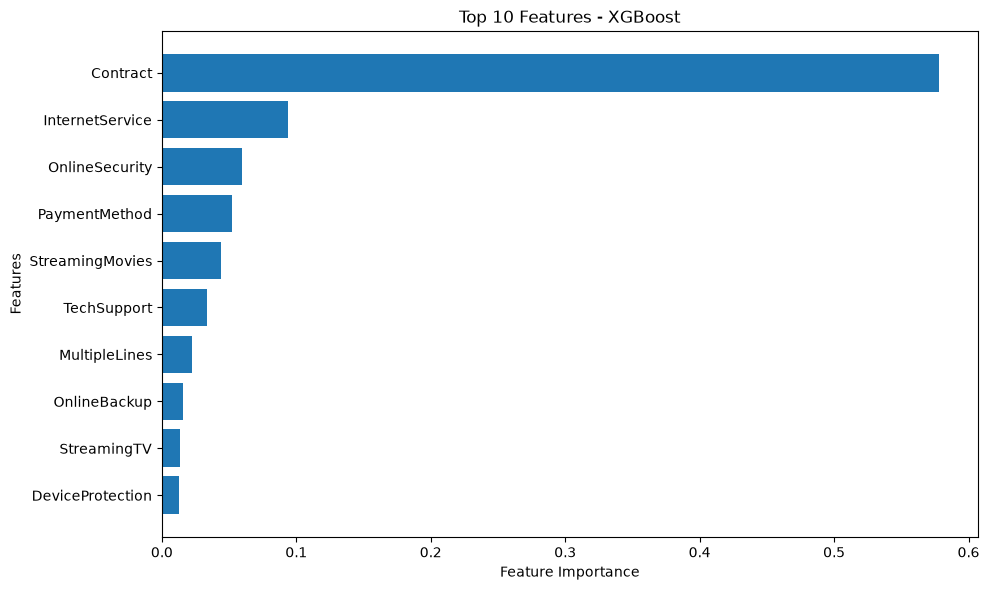

In [114]:
import matplotlib.pyplot as plt

# Random Forest feature importance
plt.figure(figsize=(10, 6))

rf_plot = rf_aggregated.head(10).sort_values(
    by='Random Forest', ascending=True
)

plt.barh(
    rf_plot['Original Feature'],
    rf_plot['Random Forest']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top 10 Features - Random Forest')
plt.tight_layout()
plt.show()


# XGBoost feature importance
plt.figure(figsize=(10, 6))

xgb_plot = xgb_aggregated.head(10).sort_values(
    by='XGBoost', ascending=True
)

plt.barh(
    xgb_plot['Original Feature'],
    xgb_plot['XGBoost']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top 10 Features - XGBoost')
plt.tight_layout()
plt.show()